# NARX maneuver prediction: Monte Carlo generation, model evaluation, and Gateway tracking

Run this notebook top-to-bottom from a repository checkout after installing the project and development dependencies (including scikit-learn). The first two computational stages generate fresh independent Monte Carlo trajectories and fit/evaluate the NARX-inspired two-stage predictor. The final sections analyze closed-loop Gateway tracking and maneuvers.

The **phase-aware inverse-guidance** ensemble produces counterfactual feasible maneuver labels without applying burns; the **closed-loop** ensemble actually schedules/applies impulses and propagates the observer/Gateway optical tracking estimators. Model scores describe *offline imitation of the STM-based teacher*, not performance of a deployed learned controller. The MC validation and test arcs remain disjoint from training arcs.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/baseline.json").exists()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the repository checkout")
preview = ROOT / "results/narx_closed_loop_preview"
full = ROOT / "results/narx_closed_loop"
dataset_dir = full if (full / "test.npz").exists() else preview
if not (dataset_dir / "test.npz").exists():
    display(Markdown("**No closed-loop results found.** Run the main notebook or `python scripts/run_closed_loop_narx.py`, then rerun this notebook."))
else:
    display(Markdown(f"Reading **{dataset_dir.relative_to(ROOT)}**. " + ("Full Monte Carlo dataset." if dataset_dir == full else "Small notebook preview, **one arc per split**; do not interpret as Monte Carlo validation.")))

**No closed-loop results found.** Run the main notebook or `python scripts/run_closed_loop_narx.py`, then rerun this notebook.

## NARX formulation and supervised targets

A nonlinear autoregressive model with exogenous inputs (NARX) approximates a control decision from causal histories rather than future truth:

$$
\hat{\boldsymbol y}_k = F_\theta\!\left(\boldsymbol z_k,\boldsymbol z_{k-1},\ldots,\boldsymbol z_{k-L+1},\boldsymbol u_{k-1},\ldots,\boldsymbol u_{k-L},\boldsymbol q_k\right),
$$

where $\boldsymbol z$ is navigation-estimated departure from the reference (position in km and velocity in m/s), $\boldsymbol u$ is *applied* $\Delta\boldsymbol v$ in rotating-frame m/s, and $\boldsymbol q_k$ includes orbital phase $[\sin\phi_k,\cos\phi_k]$, visibility, and estimated covariance. Lagged rows are only used after a complete history window is available.

The two-stage supervised predictor is

$$
\hat m_k = \mathbb{1}\!\left[p_\theta(m_k=1\mid\boldsymbol x_k) \geq \tfrac12\right],\qquad
(\widehat{\Delta\boldsymbol v}_k,\hat j_k)
= \bigl(g_\theta(\boldsymbol x_k),h_\theta(\boldsymbol x_k)\bigr)
\quad\text{for feasible requested maneuvers}.
$$

The teacher chooses among candidate delays $\tau_j$ by an STM-linearized, regularized least-squares correction followed by a nonlinear forward check:

$$
\Delta\boldsymbol v_j^* =
\underset{\Delta\boldsymbol v}{\operatorname{argmin}}\;
\left\|W\left(\boldsymbol e_{f,j}+S_j\Delta\boldsymbol v\right)\right\|_2^2
+\lambda^2\left\|\Delta\boldsymbol v\right\|_2^2,\qquad
S_j=\frac{\partial\boldsymbol e_f}{\partial\Delta\boldsymbol v}.
$$

Only finite, bounded impulses with positive nonlinear predicted improvement are feasible. A rejected request is **not** a burn label. The classifier uses requested/no-request decisions; the regression and delay-class targets only use requested, feasible examples. Hold-out F1, precision/recall, componentwise $\Delta v$ RMSE and teacher-forced delay-class accuracy test imitation, **not learned closed-loop success**.

## Step 1 — Generate the Monte Carlo ensembles

Execute the following cell to **regenerate** the phase-aware label-only dataset and the applied-burn closed-loop ensemble, saving disjoint `training.npz`, `validation.npz`, `test.npz` and metadata under `results/narx_phase_aware/` and `results/narx_closed_loop/`. This is the actual simulation, not a stale preview or an existing-files-only check.

The phase-aware ensemble reproduces the inverse-guidance generation previously discussed in Notebook 00. The closed-loop ensemble is the one used for the NARX training and Gateway performance analysis below. Full baseline runs can be computationally intensive.

In [2]:
from halo_tracking.study import load_config
from halo_tracking.narx_dataset import generate_phase_aware_dataset
from halo_tracking.closed_loop_narx import generate_closed_loop_dataset

cfg = load_config()
phase_dir = ROOT / "results/narx_phase_aware"
closed_dir = ROOT / "results/narx_closed_loop"

print("Generating phase-aware, label-only Monte Carlo arcs...", flush=True)
phase_summary = generate_phase_aware_dataset(cfg, phase_dir)
print(json.dumps(phase_summary, indent=2), flush=True)

print("Generating closed-loop Monte Carlo arcs with applied maneuvers and tracking...", flush=True)
closed_summary = generate_closed_loop_dataset(cfg, closed_dir)
print(json.dumps(closed_summary, indent=2), flush=True)
dataset_dir = closed_dir
print("Saved ensembles:", phase_dir, closed_dir, sep="\n")

Generating phase-aware, label-only Monte Carlo arcs...


{
  "training": {
    "arcs": 20,
    "decisions": 340,
    "observer_valid": 340,
    "gateway_valid": 340
  },
  "validation": {
    "arcs": 5,
    "decisions": 85,
    "observer_valid": 85,
    "gateway_valid": 85
  },
  "test": {
    "arcs": 5,
    "decisions": 85,
    "observer_valid": 85,
    "gateway_valid": 85
  }
}


Generating closed-loop Monte Carlo arcs with applied maneuvers and tracking...


{
  "training": {
    "arcs": 20,
    "decision_epochs_per_arc": 17,
    "gateway_position_within_100m_fraction": 0.3382352941176471,
    "gateway_velocity_within_limit_fraction": 0.8,
    "gateway_both_tracking_limits_fraction": 0.3382352941176471,
    "observer_total_delta_v_m_s": 36.25633269129326,
    "gateway_total_delta_v_m_s": 13.862300732749741
  },
  "validation": {
    "arcs": 5,
    "decision_epochs_per_arc": 17,
    "gateway_position_within_100m_fraction": 0.4117647058823529,
    "gateway_velocity_within_limit_fraction": 0.7764705882352941,
    "gateway_both_tracking_limits_fraction": 0.4117647058823529,
    "observer_total_delta_v_m_s": 8.92767975960915,
    "gateway_total_delta_v_m_s": 3.7876423076626513
  },
  "test": {
    "arcs": 5,
    "decision_epochs_per_arc": 17,
    "gateway_position_within_100m_fraction": 0.4,
    "gateway_velocity_within_limit_fraction": 0.8117647058823529,
    "gateway_both_tracking_limits_fraction": 0.4,
    "observer_total_delta_v_m_s": 7.211

Saved ensembles:
/home/runner/work/Halo_Orbit_Tracking/Halo_Orbit_Tracking/results/narx_phase_aware
/home/runner/work/Halo_Orbit_Tracking/Halo_Orbit_Tracking/results/narx_closed_loop


In [3]:
for label, folder in (("Phase-aware (labels only)", phase_dir), ("Closed-loop (applied burns)", closed_dir)):
    print("\n" + label)
    for split in ("training", "validation", "test"):
        with np.load(folder / f"{split}.npz") as d:
            names = set(d.files)
            key = "gateway_maneuver_required"
            arcs = int(d[key].shape[0]) if key in names else "n/a"
            decisions = int(d[key].size) if key in names else "n/a"
            triggered = int(d[key].sum()) if key in names else "n/a"
            feasible = int((d[key] & d["gateway_maneuver_valid"]).sum()) if key in names and "gateway_maneuver_valid" in names else "n/a"
            print(f"  {split}: arcs={arcs}, decisions={decisions}, Gateway requested={triggered}, feasible requested={feasible}")
print("\nNo held-out arc is used for model fitting.")


Phase-aware (labels only)
  training: arcs=20, decisions=340, Gateway requested=334, feasible requested=334
  validation: arcs=5, decisions=85, Gateway requested=84, feasible requested=84
  test: arcs=5, decisions=85, Gateway requested=85, feasible requested=85

Closed-loop (applied burns)
  training: arcs=20, decisions=340, Gateway requested=296, feasible requested=290
  validation: arcs=5, decisions=85, Gateway requested=73, feasible requested=71
  test: arcs=5, decisions=85, Gateway requested=74, feasible requested=55

No held-out arc is used for model fitting.


## Step 2 — Train and evaluate the two-stage NARX predictor

Fit on **training arcs only**, assess validation arcs, and report the separate test arcs. The implementation in `halo_tracking.two_stage_narx.evaluate_two_stage` uses causal lagged navigation and executed-control features, with boosted classifiers/regressors (a NARX-inspired nonlinear autoregressive baseline, **not** a recurrent neural network). Generated reports go to `results/narx_two_stage/metrics.json`.

This cell runs actual training and scoring, rather than merely displaying metrics if they happen to exist.

In [4]:
from halo_tracking.two_stage_narx import evaluate_two_stage

metrics_dir = ROOT / "results/narx_two_stage"
report = evaluate_two_stage(closed_dir, metrics_dir, cfg)
print("Trained on MC training arcs and evaluated on held-out validation/test arcs.")
print(json.dumps(report, indent=2))
metrics_path = metrics_dir / "metrics.json"

Trained on MC training arcs and evaluated on held-out validation/test arcs.
{
  "observer": {
    "status": "evaluated",
    "training_decisions": 260,
    "training_triggered": 41,
    "training_feasible_triggered": 41,
    "validation": {
      "evaluated_decisions": 65,
      "positive_rate": 0.12307692307692308,
      "maneuver_precision": 0.8333333333333334,
      "maneuver_recall": 0.625,
      "maneuver_f1": 0.7142857142857143,
      "confusion_matrix_true_rows": [
        [
          56,
          1
        ],
        [
          3,
          5
        ]
      ],
      "feasible_burn_examples": 8,
      "delta_v_rmse_m_s": 0.2533374350165207,
      "burn_delay_class_accuracy_teacher_forced": 0.75
    },
    "test": {
      "evaluated_decisions": 65,
      "positive_rate": 0.13846153846153847,
      "maneuver_precision": 0.6666666666666666,
      "maneuver_recall": 0.4444444444444444,
      "maneuver_f1": 0.5333333333333333,
      "confusion_matrix_true_rows": [
        [
      

## Gateway tracking after maneuvers

Position and velocity errors are calculated from the estimated and simulated true Gateway states:

$$
e_r(t)=\|\hat{\mathbf r}_{G}(t)-\mathbf r_G(t)\|,\qquad
e_v(t)=\|\hat{\mathbf v}_{G}(t)-\mathbf v_G(t)\|.
$$

The 100 m and 0.01 m/s limits must be satisfied **at the same time**. The first plot shows error histories; the table reports how often both limits are met. A successful result requires consistent performance across independent Monte Carlo realizations, not a single favorable trajectory.

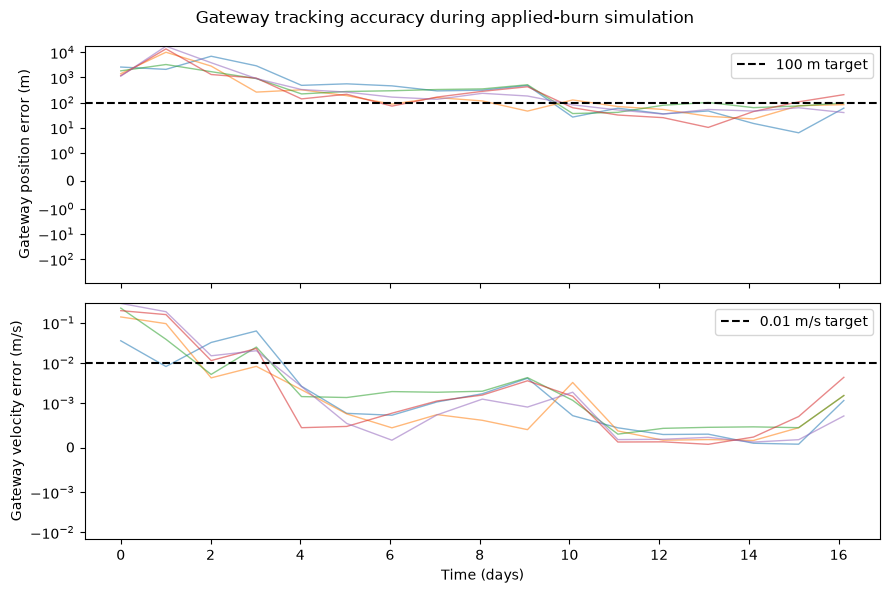

**Held-out test:** 5 episode(s). Position within 100 m: **40.0%** of decision epochs. Velocity within 0.01 m/s: **81.2%**. **Both limits simultaneously: 40.0%**. These are tracking-error metrics, not reference-departure metrics.

In [5]:
if (dataset_dir / "test.npz").exists():
    with np.load(dataset_dir / "test.npz") as d:
        t = np.array(d["decision_times_tu"]) * 375190.25852 / 86400
        p = np.array(d["gateway_tracking_position_error_km"])
        v = np.array(d["gateway_tracking_velocity_error_m_s"])
        both = (p <= 0.1) & (v <= 0.01)
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
        for i in range(min(len(p), 8)):
            ax1.plot(t, p[i]*1000, alpha=.55, linewidth=1)
            ax2.plot(t, v[i], alpha=.55, linewidth=1)
        ax1.axhline(100, linestyle="--", color="black", label="100 m target")
        ax2.axhline(.01, linestyle="--", color="black", label="0.01 m/s target")
        ax1.set_ylabel("Gateway position error (m)")
        ax2.set_ylabel("Gateway velocity error (m/s)")
        ax2.set_xlabel("Time (days)")
        ax1.legend()
        ax2.legend()
        ax1.set_yscale("symlog", linthresh=1)
        ax2.set_yscale("symlog", linthresh=.001)
        fig.suptitle("Gateway tracking accuracy during applied-burn simulation")
        plt.tight_layout()
        plt.show()
        display(Markdown(
            f"**Held-out test:** {len(p)} episode(s). Position within 100 m: **{100*np.mean(p<=.1):.1f}%** of decision epochs. "
            f"Velocity within 0.01 m/s: **{100*np.mean(v<=.01):.1f}%**. "
            f"**Both limits simultaneously: {100*np.mean(both):.1f}%**. "
            "These are tracking-error metrics, not reference-departure metrics."
        ))

## Maneuver labels versus executed burns

The STM-based guidance algorithm requests a correction when estimated departure crosses a trigger. A **valid label** can be a zero burn when no correction is needed. Therefore valid-label counts should not be read as successful maneuvers.

This section separates requested corrections, accepted corrections, rejected requests and actual executed impulses. A burn can be selected at one decision and executed between two decisions, so the saved applied-burn history must be interpreted with its recorded execution time.

In [6]:
if (dataset_dir / "test.npz").exists():
    with np.load(dataset_dir / "test.npz") as d:
        lines = ["| Spacecraft | Decisions | Requested | Feasible requested | Rejected requested | Nonzero applied-burn records |", "|---|---:|---:|---:|---:|---:|"]
        for name in ("observer", "gateway"):
            requested = np.asarray(d[name + "_maneuver_required"], dtype=bool)
            valid = np.asarray(d[name + "_maneuver_valid"], dtype=bool)
            applied = np.linalg.norm(d[name + "_applied_delta_v_rotating_m_s"], axis=-1) > 0
            lines.append(f"| {name.title()} | {requested.size} | {requested.sum()} | {(requested & valid).sum()} | {(requested & ~valid).sum()} | {applied.sum()} |")
        display(Markdown("\n".join(lines)))
        display(Markdown("The applied-burn count reflects **saved nonzero records**, not necessarily distinct commands when multiple impulses occur between decision epochs."))

| Spacecraft | Decisions | Requested | Feasible requested | Rejected requested | Nonzero applied-burn records |
|---|---:|---:|---:|---:|---:|
| Observer | 85 | 14 | 14 | 0 | 14 |
| Gateway | 85 | 74 | 55 | 19 | 47 |

The applied-burn count reflects **saved nonzero records**, not necessarily distinct commands when multiple impulses occur between decision epochs.

## Two-stage learned maneuver predictor

The first model predicts **maneuver or no maneuver**. For requested feasible burns, the next models predict the three components of Δv and one of four burn-delay classes. The classifier is evaluated with precision, recall and F1. The Δv predictor uses RMSE in m/s, and the burn-delay classifier reports accuracy.

The learned-policy metrics measure **imitation of the STM guidance labels**, not whether predicted maneuvers maintain Gateway tracking. A learned closed-loop evaluation is needed before claiming tracking performance from NARX.

In [7]:
metrics_path = ROOT / "results/narx_two_stage/metrics.json"
if metrics_path.exists():
    metrics = json.loads(metrics_path.read_text())
    lines = ["| Spacecraft | Split | F1 | Precision | Recall | Δv RMSE (m/s) | Delay accuracy |", "|---|---|---:|---:|---:|---:|---:|"]
    for name, result in metrics.items():
        for split in ("validation", "test"):
            m = result.get(split)
            if m is None:
                continue
            rmse = "N/A" if m["delta_v_rmse_m_s"] is None else f'{m["delta_v_rmse_m_s"]:.5f}'
            delay = "N/A" if m["burn_delay_class_accuracy_teacher_forced"] is None else f'{100*m["burn_delay_class_accuracy_teacher_forced"]:.1f}%'
            lines.append(f'| {name.title()} | {split} | {m["maneuver_f1"]:.3f} | {m["maneuver_precision"]:.3f} | {m["maneuver_recall"]:.3f} | {rmse} | {delay} |')
    display(Markdown("\n".join(lines)))
else:
    display(Markdown("**Learned-model scores have not been generated in this checkout.** Run `python scripts/run_two_stage_narx.py` to generate Monte Carlo data and evaluate the two-stage predictor, then rerun this notebook. No numerical learning performance is assumed."))

| Spacecraft | Split | F1 | Precision | Recall | Δv RMSE (m/s) | Delay accuracy |
|---|---|---:|---:|---:|---:|---:|
| Observer | validation | 0.714 | 0.833 | 0.625 | 0.25334 | 75.0% |
| Observer | test | 0.533 | 0.667 | 0.444 | 0.30969 | 77.8% |
| Gateway | validation | 0.937 | 0.897 | 0.981 | 0.00523 | 68.6% |
| Gateway | test | 0.953 | 0.962 | 0.944 | 0.00426 | 63.4% |